# Week 6 Assignment — Customer Support Intent Classification

**Project connection:** AI-Based Smart Queue & Time Management System  
**Course:** TECH 405 — Artificial Neural Network and Deep Learning  
**Student:** Bishwadeep Rai | Westcliff University, California  
**Instructor:** Professor Aashish Dhakal  
**Task:** Classify a customer-support request into one of 27 service intents.  
**Models:** Feed-forward neural network (MLP) and recurrent deep-learning LSTM.



## 1. Problem statement and relationship to the queue project

It is up to a queueing system to determine which queue should receive the newly made request. In this case, **intent routing** is formulated as a classification problem. Specifically, given only the customer's `instruction`, the model has to identify its `intent` (for instance, `track_order`, `payment_issue`, `recover_password`). Routing of requests into appropriate service queues will be helpful as one of the components of the Smart Queue system; this task does not involve prediction of waiting time or service level.

There are labels provided in the data, so the provided `intent` is the true label. Train, validation, and test sets are stratified and disjoint from each other. Validation dataset picks the epoch with the highest macro F1 score, while test data serves for final comparison of the models. There is a majority class baseline.

**Important limitation:** According to Hugging Face, this is a *hybrid synthetic* dataset that was created using NLP/NLG and automated labeling. Provided labels serve as reference labels for this coursework, but the model's performance on this data does not imply its performance on real customer traffic. This data source is an English retail customer service dataset.

## 2. Dataset source, fields, and reproducibility

- **Dataset:** Bitext — Customer Service Tagged Training Dataset for LLM-based Virtual Assistants
- **Hugging Face dataset page:** [bitext/Bitext-customer-support-llm-chatbot-training-dataset](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset)
- **CSV file:** [Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset/resolve/main/Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv)
- **Source-reported size:** 26,872 request/response examples; 27 intents in 10 categories.
- **License declared in dataset metadata:** CDLA-Sharing-1.0. Review the dataset page/license terms before redistributing data.
- **Input feature:** `instruction` — the incoming customer request.
- **Ground-truth target:** `intent` — the request's labeled intent.
- **Excluded columns:** `response`, `category`, `flags`, and entity annotations are not model inputs. `category` is a coarser correlated label and would make intent prediction artificially easier; the response is only available after routing.



In [1]:
from collections import Counter
from copy import deepcopy
from pathlib import Path
import json
import os
import random
import re
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, roc_curve, auc
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__} | Device: {DEVICE} | Seed: {SEED}")

c:\Users\MSI-1\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\MSI-1\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


PyTorch: 2.6.0+cu126 | Device: cuda | Seed: 42


In [2]:
DATASET_URL = (
    "https://huggingface.co/datasets/bitext/"
    "Bitext-customer-support-llm-chatbot-training-dataset/resolve/main/"
    "Bitext_Sample_Customer_Support_Training_Dataset_27K_responses-v11.csv"
)
DATA_CACHE = Path.home() / ".cache" / "smart_queue_week6"
DATA_CACHE.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_CACHE / "bitext_customer_support.csv"
if not CSV_PATH.exists():
    print("Downloading the public dataset from Hugging Face...")
    request = urllib.request.Request(DATASET_URL, headers={"User-Agent": "Week6-Assignment/1.0"})
    with urllib.request.urlopen(request, timeout=120) as response:
        CSV_PATH.write_bytes(response.read())

df = pd.read_csv(CSV_PATH)
required_columns = {"instruction", "intent", "category", "response", "flags"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Expected dataset columns are missing: {sorted(missing_columns)}")
df = df.loc[:, ["instruction", "intent", "category", "response", "flags"]].copy()
if df[["instruction", "intent"]].isna().any().any():
    raise ValueError("Incoming instructions and ground-truth intents must not be missing.")
df["instruction"] = df["instruction"].astype(str).str.strip()
df["intent"] = df["intent"].astype(str).str.strip()
if (df["instruction"] == "").any() or (df["intent"] == "").any():
    raise ValueError("Empty instructions or intent labels were found; inspect the source data.")
print(f"Loaded cached dataset: {CSV_PATH.name}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} selected source fields")
display(df[["instruction", "category", "intent"]].head())

Loaded cached dataset: bitext_customer_support.csv
Shape: 26,872 rows x 5 selected source fields


,instruction,category,intent
0,question about cancelling order {{Order Number}},ORDER,cancel_order
1,i have a question about cancelling oorder {{Or...,ORDER,cancel_order
2,i need help cancelling puchase {{Order Number}},ORDER,cancel_order
3,I need to cancel purchase {{Order Number}},ORDER,cancel_order
4,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order


Unique intent labels: 27
Exact duplicate instructions: 2,237
Missing target values: 0
Intent label counts (ground-truth distribution):


,examples
intent,
cancel_order,998
change_order,997
change_shipping_address,973
check_cancellation_fee,950
check_invoice,1000
check_payment_methods,999
check_refund_policy,997
complaint,1000
contact_customer_service,1000


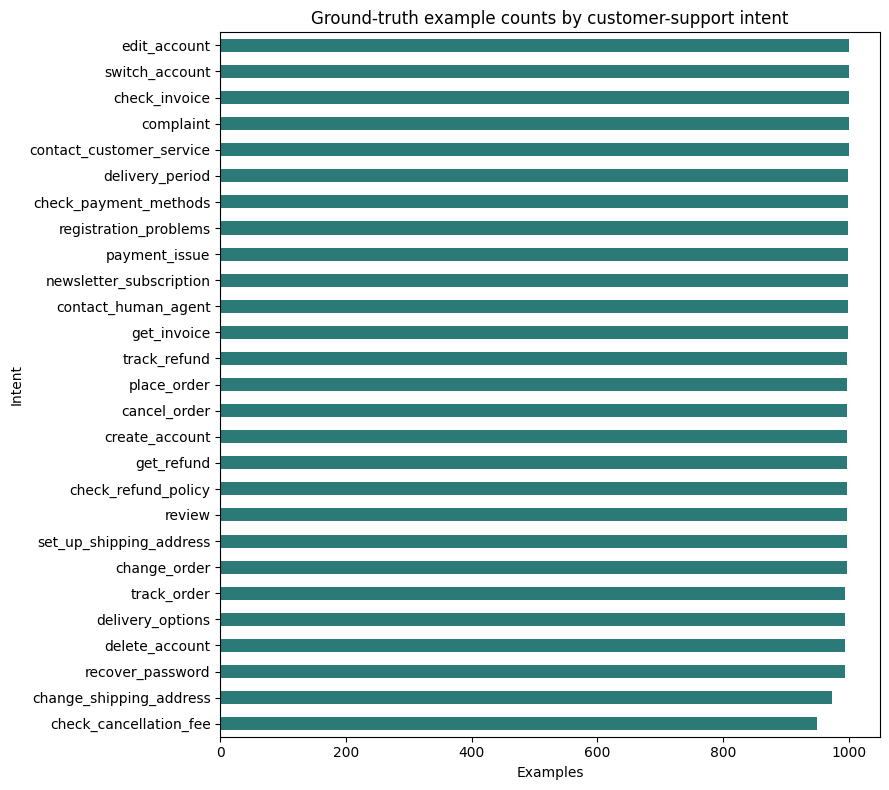

In [3]:
label_counts = df["intent"].value_counts().sort_index()
print(f"Unique intent labels: {df['intent'].nunique()}")
print(f"Exact duplicate instructions: {df['instruction'].duplicated().sum():,}")
print(f"Missing target values: {df['intent'].isna().sum()}")
print("Intent label counts (ground-truth distribution):")
display(label_counts.rename("examples").to_frame())
ax = label_counts.sort_values().plot.barh(figsize=(9, 8), color="#2b7a78")
ax.set(title="Ground-truth example counts by customer-support intent", xlabel="Examples", ylabel="Intent")
plt.tight_layout()
plt.show()

## 3. Preparation and leakage controls

Input only consists of the text request. Response, category, and flags are left out because they cannot be used as they would be either future information or an inference shortcut. Transformations on text data can only be learned through training. Both models employ the same training/development/test split and labeling of intents. All 27 intents have representation in each set.

In [4]:
texts = df["instruction"].to_numpy()
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["intent"])
class_names = label_encoder.classes_
all_indices = np.arange(len(df))
train_idx, holdout_idx = train_test_split(
    all_indices, test_size=0.30, random_state=SEED, stratify=y
)
valid_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, random_state=SEED, stratify=y[holdout_idx]
)
y_train, y_valid, y_test = y[train_idx], y[valid_idx], y[test_idx]
print(f"Classes: {len(class_names)}")
print(f"Train: {len(train_idx):,} | Validation: {len(valid_idx):,} | Test: {len(test_idx):,}")
assert set(train_idx).isdisjoint(valid_idx) and set(train_idx).isdisjoint(test_idx)
assert set(valid_idx).isdisjoint(test_idx)
assert len(np.unique(y_train)) == len(class_names)
assert len(np.unique(y_valid)) == len(class_names)
assert len(np.unique(y_test)) == len(class_names)

Classes: 27
Train: 18,810 | Validation: 4,031 | Test: 4,031


## 4. Model 1 — Feed-forward neural network (MLP)

The TF-IDF representation of words/phrases (unigram and bigram) is provided as input to two fully-connected hidden layers using ReLU activation and dropout. The 27-node output layer, which is softmax equivalent, is learned using cross-entropy. The sparse TF-IDF feature vectors are converted into dense form batch by batch to limit the memory footprint. The macro F1 on the validation set picks the checkpoint model.

In [5]:
vectorizer = TfidfVectorizer(
    lowercase=True, ngram_range=(1, 2), max_features=12_000,
    min_df=2, sublinear_tf=True, dtype=np.float32
)
X_train_tfidf = vectorizer.fit_transform(texts[train_idx])
X_valid_tfidf = vectorizer.transform(texts[valid_idx])
X_test_tfidf = vectorizer.transform(texts[test_idx])
print(f"Training-only TF-IDF vocabulary: {X_train_tfidf.shape[1]:,} features")

class SparseTextMLP(nn.Module):
    def __init__(self, input_size, number_of_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 256), nn.ReLU(), nn.Dropout(0.35),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.25),
            nn.Linear(128, number_of_classes),
        )

    def forward(self, features):
        return self.network(features)

mlp = SparseTextMLP(X_train_tfidf.shape[1], len(class_names)).to(DEVICE)
mlp_optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

def sparse_predict_proba(model, matrix, batch_size=512):
    model.eval()
    probability_batches = []
    with torch.no_grad():
        for start in range(0, matrix.shape[0], batch_size):
            batch = matrix[start:start + batch_size].toarray()
            features = torch.from_numpy(batch).to(DEVICE)
            probability_batches.append(torch.softmax(model(features), dim=1).cpu().numpy())
    return np.concatenate(probability_batches, axis=0)

def train_sparse_mlp(model, optimizer, train_matrix, train_labels, valid_matrix, valid_labels, epochs=10, patience=2):
    history = {"loss": [], "val_macro_f1": []}
    best_f1, best_state, wait = -1.0, None, 0
    rng = np.random.default_rng(SEED)
    y_valid_t = np.asarray(valid_labels)
    for epoch in range(epochs):
        model.train()
        order = rng.permutation(train_matrix.shape[0])
        losses = []
        for start in range(0, len(order), 256):
            batch_ids = order[start:start + 256]
            xb = torch.from_numpy(train_matrix[batch_ids].toarray()).to(DEVICE)
            yb = torch.as_tensor(train_labels[batch_ids], dtype=torch.long, device=DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            losses.append(float(loss.item()))
        valid_probs = sparse_predict_proba(model, valid_matrix)
        valid_f1 = f1_score(y_valid_t, valid_probs.argmax(axis=1), average="macro", zero_division=0)
        history["loss"].append(float(np.mean(losses)))
        history["val_macro_f1"].append(float(valid_f1))
        print(f"MLP epoch {epoch + 1:02d}: loss={history['loss'][-1]:.4f}, validation macro F1={valid_f1:.4f}")
        if valid_f1 > best_f1:
            best_f1, best_state, wait = valid_f1, deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping: validation macro F1 did not improve.")
                break
    if best_state is None:
        raise RuntimeError("MLP training did not produce a validation checkpoint.")
    model.load_state_dict(best_state)
    return history

mlp_history = train_sparse_mlp(
    mlp, mlp_optimizer, X_train_tfidf, y_train, X_valid_tfidf, y_valid
)
mlp_test_probs = sparse_predict_proba(mlp, X_test_tfidf)

Training-only TF-IDF vocabulary: 4,880 features
MLP epoch 01: loss=2.6373, validation macro F1=0.9394
MLP epoch 02: loss=0.3834, validation macro F1=0.9899
MLP epoch 03: loss=0.0934, validation macro F1=0.9938
MLP epoch 04: loss=0.0523, validation macro F1=0.9948
MLP epoch 05: loss=0.0370, validation macro F1=0.9953
MLP epoch 06: loss=0.0294, validation macro F1=0.9948
MLP epoch 07: loss=0.0251, validation macro F1=0.9948
Early stopping: validation macro F1 did not improve.


## 5. Model 2 — Recurrent deep-learning LSTM

In this model, tokens from the training dataset are encoded as integers and embedded before processing the input sequence using an LSTM network built in PyTorch. After the embedding is done, the final hidden state is mapped to 27 intent scores by a fully connected layer. For creating vocabulary, only the training data is used, and all validation/test tokens not present in vocab are mapped to '<UNK>'.

In [6]:
TOKEN_PATTERN = re.compile(r"[a-z0-9']+")
MAX_VOCAB = 15_000
MAX_LENGTH = 48
BATCH_SIZE = 128

def tokenize(text):
    return TOKEN_PATTERN.findall(str(text).lower())

token_counts = Counter(token for index in train_idx for token in tokenize(texts[index]))
vocabulary = {"<PAD>": 0, "<UNK>": 1}
for word, _ in token_counts.most_common(MAX_VOCAB - len(vocabulary)):
    vocabulary[word] = len(vocabulary)

def encode_texts(indices):
    encoded = np.zeros((len(indices), MAX_LENGTH), dtype=np.int64)
    lengths = np.zeros(len(indices), dtype=np.int64)
    for row, index in enumerate(indices):
        ids = [vocabulary.get(token, 1) for token in tokenize(texts[index])[:MAX_LENGTH]]
        if not ids:
            ids = [1]
        encoded[row, :len(ids)] = ids
        lengths[row] = len(ids)
    return encoded, lengths

train_tokens, train_lengths = encode_texts(train_idx)
valid_tokens, valid_lengths = encode_texts(valid_idx)
test_tokens, test_lengths = encode_texts(test_idx)
print(f"Training-only token vocabulary: {len(vocabulary):,} | Maximum sequence length: {MAX_LENGTH}")

class IntentLSTM(nn.Module):
    def __init__(self, vocab_size, number_of_classes, embedding_size=64, hidden_size=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=0)
        self.lstm = nn.LSTM(embedding_size, hidden_size, batch_first=True)
        self.dropout = nn.Dropout(0.30)
        self.output = nn.Linear(hidden_size, number_of_classes)

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        return self.output(self.dropout(hidden[-1]))

def make_loader(token_ids, lengths, labels, shuffle):
    dataset = TensorDataset(
        torch.from_numpy(token_ids), torch.from_numpy(lengths),
        torch.as_tensor(labels, dtype=torch.long)
    )
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)

train_loader = make_loader(train_tokens, train_lengths, y_train, True)
valid_loader = make_loader(valid_tokens, valid_lengths, y_valid, False)
test_loader = make_loader(test_tokens, test_lengths, y_test, False)
lstm = IntentLSTM(len(vocabulary), len(class_names)).to(DEVICE)
lstm_optimizer = torch.optim.Adam(lstm.parameters(), lr=1e-3)

def lstm_predict_proba(model, loader):
    model.eval()
    probability_batches = []
    with torch.no_grad():
        for token_ids, lengths, _ in loader:
            logits = model(token_ids.to(DEVICE), lengths)
            probability_batches.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(probability_batches, axis=0)

def train_lstm(model, optimizer, training_loader, validation_loader, epochs=8, patience=2):
    history = {"loss": [], "val_macro_f1": []}
    best_f1, best_state, wait = -1.0, None, 0
    for epoch in range(epochs):
        model.train()
        losses = []
        for token_ids, lengths, labels in training_loader:
            token_ids, labels = token_ids.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(token_ids, lengths), labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            losses.append(float(loss.item()))
        valid_probs = lstm_predict_proba(model, validation_loader)
        valid_labels = validation_loader.dataset.tensors[2].numpy()
        valid_f1 = f1_score(valid_labels, valid_probs.argmax(axis=1), average="macro", zero_division=0)
        history["loss"].append(float(np.mean(losses)))
        history["val_macro_f1"].append(float(valid_f1))
        print(f"LSTM epoch {epoch + 1:02d}: loss={history['loss'][-1]:.4f}, validation macro F1={valid_f1:.4f}")
        if valid_f1 > best_f1:
            best_f1, best_state, wait = valid_f1, deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping: validation macro F1 did not improve.")
                break
    if best_state is None:
        raise RuntimeError("LSTM training did not produce a validation checkpoint.")
    model.load_state_dict(best_state)
    return history

lstm_history = train_lstm(lstm, lstm_optimizer, train_loader, valid_loader)
lstm_test_probs = lstm_predict_proba(lstm, test_loader)

Training-only token vocabulary: 2,353 | Maximum sequence length: 48
LSTM epoch 01: loss=2.0060, validation macro F1=0.8520
LSTM epoch 02: loss=0.4487, validation macro F1=0.9490
LSTM epoch 03: loss=0.1917, validation macro F1=0.9752
LSTM epoch 04: loss=0.1063, validation macro F1=0.9807
LSTM epoch 05: loss=0.0704, validation macro F1=0.9854
LSTM epoch 06: loss=0.0485, validation macro F1=0.9876
LSTM epoch 07: loss=0.0352, validation macro F1=0.9869
LSTM epoch 08: loss=0.0265, validation macro F1=0.9891


## 6. Held-out evaluation and direct model comparison

Both models are scored against the same test ground truth. Precision, recall, and F1 are **macro averages** (each intent contributes equally); ROC-AUC is the macro one-vs-rest multiclass AUC. Accuracy is shown as a secondary measure. The baseline always predicts the most frequent training-set intent. No threshold is tuned on the test partition.

In [7]:
majority_label = int(np.bincount(y_train).argmax())
majority_predictions = np.full_like(y_test, majority_label)

def score_model(name, y_true, probabilities):
    predictions = probabilities.argmax(axis=1)
    return {
        "model": name,
        "accuracy": float(accuracy_score(y_true, predictions)),
        "precision_macro": float(precision_score(y_true, predictions, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, predictions, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, predictions, average="macro", zero_division=0)),
        "roc_auc_ovr_macro": float(roc_auc_score(y_true, probabilities, multi_class="ovr", average="macro")),
    }

results = pd.DataFrame([
    {"model": "Majority baseline", "accuracy": float(accuracy_score(y_test, majority_predictions)),
     "precision_macro": float(precision_score(y_test, majority_predictions, average="macro", zero_division=0)),
     "recall_macro": float(recall_score(y_test, majority_predictions, average="macro", zero_division=0)),
     "f1_macro": float(f1_score(y_test, majority_predictions, average="macro", zero_division=0)),
     "roc_auc_ovr_macro": float("nan")},
    score_model("Feed-forward MLP", y_test, mlp_test_probs),
    score_model("PyTorch LSTM", y_test, lstm_test_probs),
]).set_index("model")
display(results.round(4))

mlp_predictions = mlp_test_probs.argmax(axis=1)
lstm_predictions = lstm_test_probs.argmax(axis=1)
mlp_report = pd.DataFrame(classification_report(
    y_test, mlp_predictions, labels=np.arange(len(class_names)),
    target_names=class_names, output_dict=True, zero_division=0
)).T
lstm_report = pd.DataFrame(classification_report(
    y_test, lstm_predictions, labels=np.arange(len(class_names)),
    target_names=class_names, output_dict=True, zero_division=0
)).T
print("Per-intent held-out report — MLP:")
display(mlp_report.loc[class_names, ["precision", "recall", "f1-score", "support"]].round(3))
print("Per-intent held-out report — LSTM:")
display(lstm_report.loc[class_names, ["precision", "recall", "f1-score", "support"]].round(3))

,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro
model,,,,,
Majority baseline,0.0372,0.0014,0.0370,0.0027,NaN
Feed-forward MLP,0.9938,0.9938,0.9938,0.9938,1.0
PyTorch LSTM,0.9906,0.9907,0.9906,0.9906,1.0


Per-intent held-out report — MLP:


,precision,recall,f1-score,support
cancel_order,0.993,0.993,0.993,149.0
change_order,0.986,0.967,0.976,150.0
change_shipping_address,0.980,0.993,0.986,146.0
check_cancellation_fee,1.000,1.000,1.000,142.0
check_invoice,0.980,0.993,0.987,150.0
check_payment_methods,1.000,1.000,1.000,150.0
check_refund_policy,1.000,1.000,1.000,150.0
complaint,1.000,1.000,1.000,150.0
contact_customer_service,0.993,0.993,0.993,150.0
contact_human_agent,0.993,1.000,0.997,150.0


Per-intent held-out report — LSTM:


,precision,recall,f1-score,support
cancel_order,1.000,0.960,0.979,149.0
change_order,0.973,0.967,0.970,150.0
change_shipping_address,0.986,1.000,0.993,146.0
check_cancellation_fee,1.000,1.000,1.000,142.0
check_invoice,0.980,0.980,0.980,150.0
check_payment_methods,1.000,0.987,0.993,150.0
check_refund_policy,1.000,0.993,0.997,150.0
complaint,1.000,1.000,1.000,150.0
contact_customer_service,1.000,0.993,0.997,150.0
contact_human_agent,0.993,1.000,0.997,150.0


C:\Users\MSI-1\AppData\Local\Temp\ipykernel_23524\2470800037.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


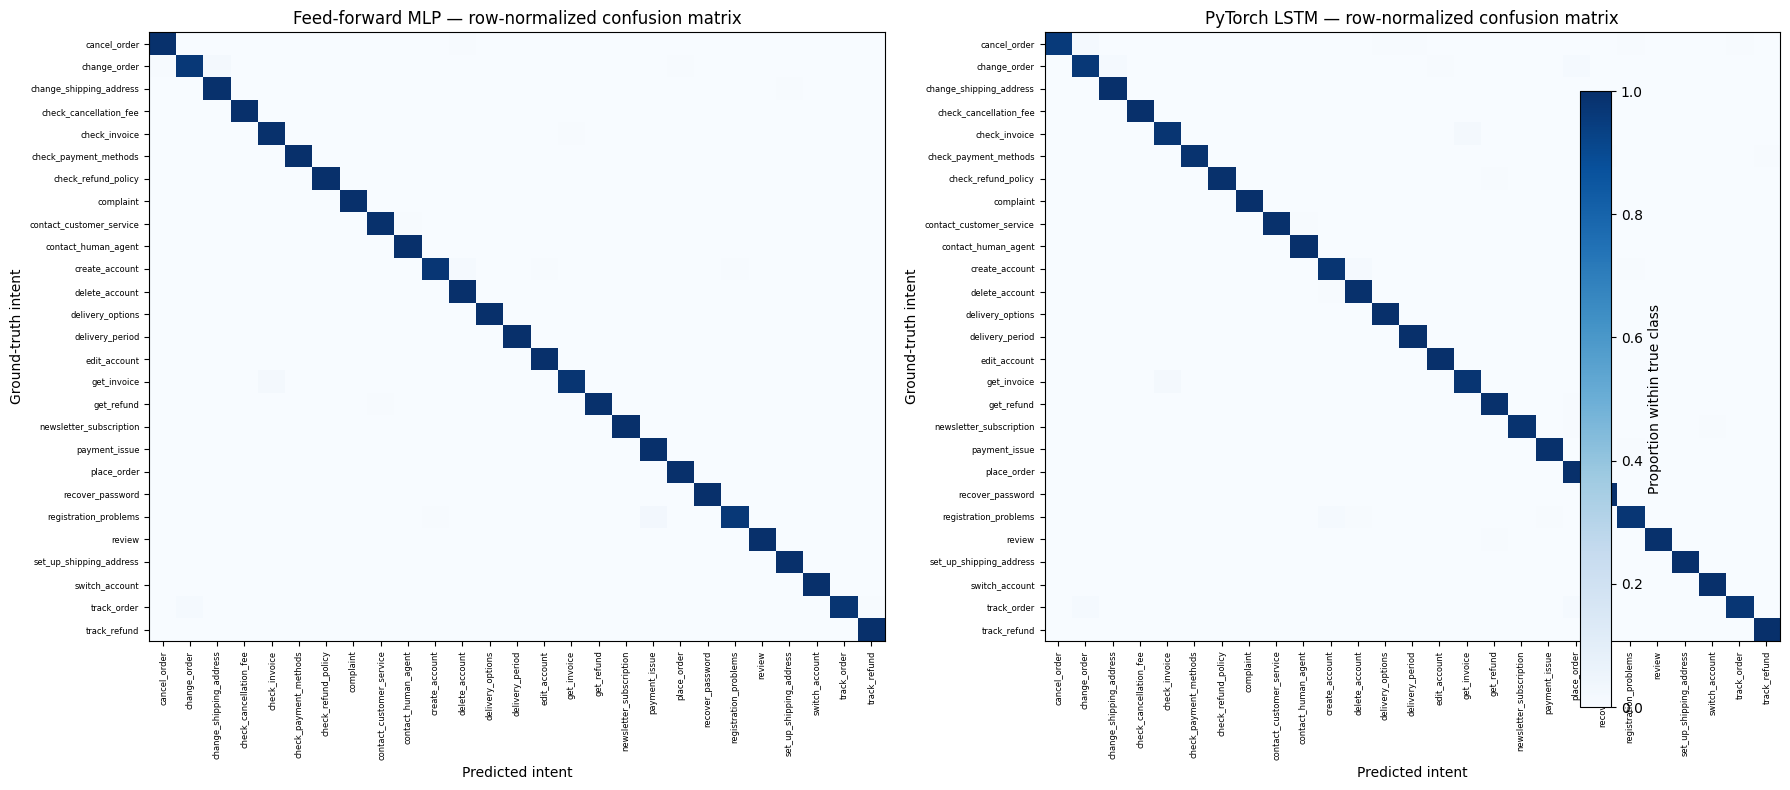

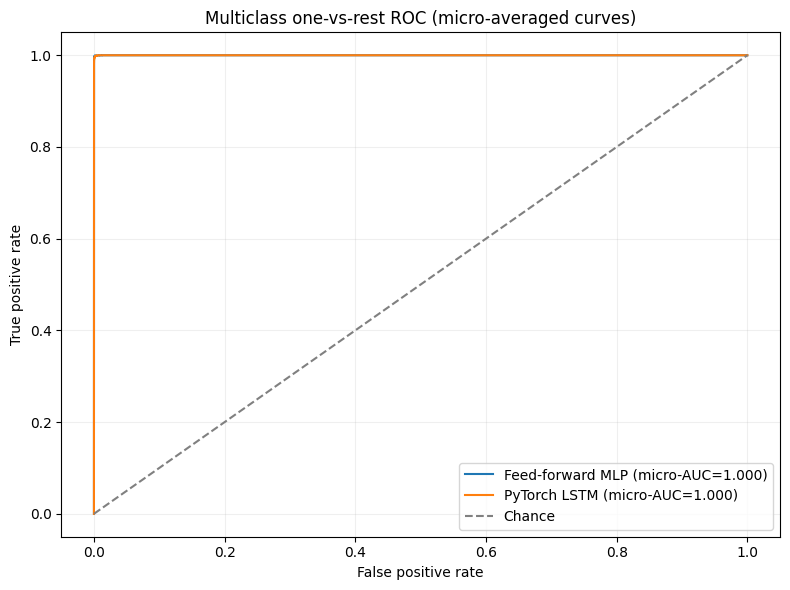

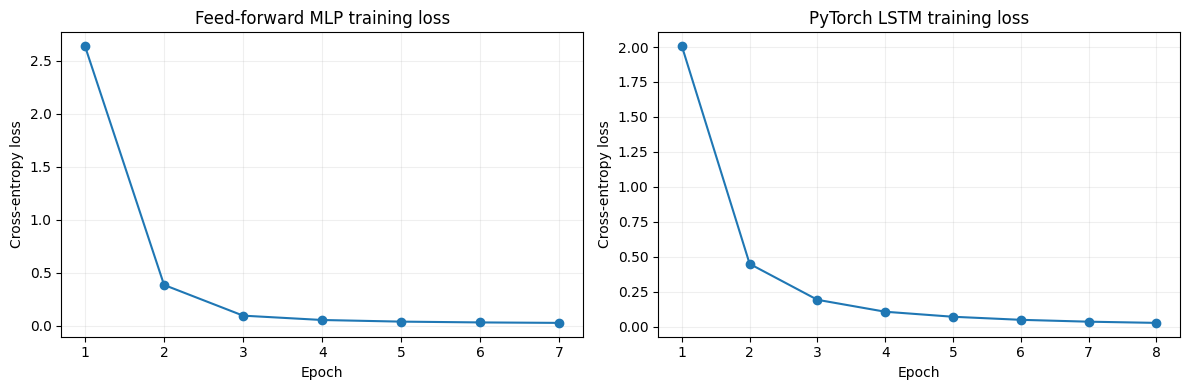

Saved report figures to images/ and results to outputs/.


In [8]:
OUTPUT_DIR = Path.cwd() / "outputs"
IMAGE_DIR = Path.cwd() / "images"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for axis, predictions, title in [
    (axes[0], mlp_predictions, "Feed-forward MLP"),
    (axes[1], lstm_predictions, "PyTorch LSTM"),
]:
    matrix = confusion_matrix(y_test, predictions, labels=np.arange(len(class_names)), normalize="true")
    image = axis.imshow(matrix, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    axis.set_title(f"{title} — row-normalized confusion matrix")
    axis.set_xlabel("Predicted intent")
    axis.set_ylabel("Ground-truth intent")
    axis.set_xticks(np.arange(len(class_names)), class_names, rotation=90, fontsize=6)
    axis.set_yticks(np.arange(len(class_names)), class_names, fontsize=6)
fig.colorbar(image, ax=axes, fraction=0.025, pad=0.02, label="Proportion within true class")
fig.tight_layout()
confusion_path = IMAGE_DIR / "confusion_matrices.png"
fig.savefig(confusion_path, dpi=180, bbox_inches="tight")
plt.show()

y_test_binary = label_binarize(y_test, classes=np.arange(len(class_names)))
fig, ax = plt.subplots(figsize=(8, 6))
for name, probabilities in [("Feed-forward MLP", mlp_test_probs), ("PyTorch LSTM", lstm_test_probs)]:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test_binary.ravel(), probabilities.ravel())
    micro_auc = auc(false_positive_rate, true_positive_rate)
    ax.plot(false_positive_rate, true_positive_rate, label=f"{name} (micro-AUC={micro_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set(title="Multiclass one-vs-rest ROC (micro-averaged curves)", xlabel="False positive rate", ylabel="True positive rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.2)
fig.tight_layout()
roc_path = IMAGE_DIR / "roc_curves.png"
fig.savefig(roc_path, dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, history, name in [
    (axes[0], mlp_history, "Feed-forward MLP"),
    (axes[1], lstm_history, "PyTorch LSTM"),
]:
    axis.plot(range(1, len(history["loss"]) + 1), history["loss"], marker="o", label="Training loss")
    axis.set(title=f"{name} training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
    axis.grid(alpha=0.2)
fig.tight_layout()
loss_path = IMAGE_DIR / "training_loss.png"
fig.savefig(loss_path, dpi=180, bbox_inches="tight")
plt.show()

results_path = OUTPUT_DIR / "week6_results.json"
results_path.write_text(json.dumps({
    "dataset": "Bitext Customer Service Tagged Training Dataset",
    "dataset_url": "https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset",
    "source_rows": int(len(df)), "number_of_intents": int(len(class_names)),
    "train_rows": int(len(train_idx)), "validation_rows": int(len(valid_idx)), "test_rows": int(len(test_idx)),
    "seed": SEED, "class_names": class_names.tolist(),
    "metrics": results.replace({np.nan: None}).to_dict(orient="index"),
    "mlp_validation_macro_f1_by_epoch": mlp_history["val_macro_f1"],
    "lstm_validation_macro_f1_by_epoch": lstm_history["val_macro_f1"],
}, indent=2), encoding="utf-8")
print("Saved report figures to images/ and results to outputs/")

## 7. Interpretation and limitations

Apply the actual test set accuracy numbers and confusion matrices above to find out which model performs better; use macro measures as all 27 intents need to be considered, not only those that appear frequently. Better ROC-AUC means better ordering over one-vs-rest pairs of classes, and argmax-based confusion matrix demonstrates the routing decision at the end of the day. Inspect intent-level numbers before concluding from any aggregated measure.

The measure comparison applies to this particular train-test split and dataset only. The list of important limitations here: source of data — artificial/automatic labels, English only inputs, retail-focused intent space, possibly used templates, and no independent verification on some real-world call-centre queue. Commercial use of such a routing system requires proper validation on reviewed requests and more.

In [9]:
sample_requests = [
    "Where can I see the status of my order?",
    "I was charged twice and need help with my payment.",
    "Please help me reset the password for my account.",
]
sample_matrix = vectorizer.transform(sample_requests)
sample_probs = sparse_predict_proba(mlp, sample_matrix)
sample_predictions = label_encoder.inverse_transform(sample_probs.argmax(axis=1))
display(pd.DataFrame({
    "request": sample_requests,
    "predicted_intent_by_mlp": sample_predictions,
    "confidence": sample_probs.max(axis=1).round(4),
}))

,request,predicted_intent_by_mlp,confidence
0,Where can I see the status of my order?,track_refund,0.4618
1,I was charged twice and need help with my paym...,payment_issue,0.2907
2,Please help me reset the password for my account.,recover_password,0.9939
